# CalcFADC: TPC の FADC 波形 → 電荷

各ボードの FADC は 4 ch で、1 ch が 32 本のストリップの信号の和です(全部でアノード 48 ch、カソード 48 ch。ch の番号は 4 × ボード + ch)。
`CalcFADC` は、ch ごとの 512 サンプルの波形から電荷を求めます。

| 手順 | 中身 | パラメータ |
|---|---|---|
| 1. 波形 | カソードは極性が逆なので `1023 − ADC` にする(`ReadData::Get_TPC_FADC`) | |
| 2. ベースライン | 最初の 30 サンプルの平均 | `base_window` |
| 3. 電荷 | ベースラインより `threshold`(20 ADU)以上高いサンプルについて、ベースラインからの高さを足す [ADU × サンプル] | `threshold` |

電荷は後ろの `TPC_Calibration` に渡すだけで、**ROOT ファイルには何も書かず、印(イベントの選択のフラグ)も付けません**。イベントは飛ばしません(SMILE_tool_box と同じ)。

ベースラインや電荷の分布、1-hit スペクトル(ゲインマップの材料)は、**後段の解析**で作ります。
`smile3_raw`(`ReadData → RawTreeWriter_sm3`)の生データのツリーの波形から、`scripts/calib/make_tpc_spec1hit.py` が CalcFADC と同じ計算で電荷を出し、
ヒストグラムにします(EricaNext_try の `4_MakeCalibration/GainMap` と同じやり方)。

| `make_tpc_spec1hit.py` の出力 | 中身 |
|---|---|
| `Baseline_Anode`, `Baseline_Cathode`, `Charge_Anode`, `Charge_Cathode` | ch ごとのベースラインと電荷(電荷のある ch だけ) |
| `Anode_1Hit_Axx_Cyy`, `Cathode_1Hit_Axx_Cyy` | 1-hit スペクトル: アノード 1 ch・同じパネルのカソード 1 ch だけに電荷があるイベントの、ch の組 (xx, yy) ごとの電荷 |
| `Anode_1Hit_board_Ai_Cj`, `Cathode_1Hit_board_Ai_Cj` | 同じものをボードの組ごとにまとめたもの(ボードの 4 ch の和) |
| `qa/<出力名>_board.png` | パネルごとのボードの組の 1-hit スペクトル(確認の図) |

2026-11-06 までは、この図を CalcFADC の中で作っていました(`save_TH_plots`, `save_board_plots`)。同じイベントで、そのときの図(中身のある 808 個)と
`make_tpc_spec1hit.py` の図がビンの中身まで一致することを確かめてから、CalcFADC から外しました。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有、git には入れない)
CACHE.mkdir(exist_ok=True)

def th2(h):
    """ROOT の TH2 -> (中身 [x のビン, y のビン], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    dt = np.float32 if h.InheritsFrom("TArrayF") else np.float64   # TH2F / TH2D
    a = np.frombuffer(h.GetArray(), dtype=dt, count=(nx + 2) * (ny + 2)).reshape(ny + 2, nx + 2).astype(float)
    ex = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ey = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return a[1:-1, 1:-1].T.copy(), ex, ey

def th1(h):
    """ROOT の TH1 -> (中身, ビンの中心)"""
    n = h.GetNbinsX()
    return np.array([h.GetBinContent(i) for i in range(1, n + 1)]), np.array([h.GetBinCenter(i) for i in range(1, n + 1)])

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> numpy の配列のリスト"""
    return [np.asarray(v) for v in column]

def show_params(config, module):
    """設定ファイルの、あるモジュールのパラメータを、説明(_doc)と単位(_units)つきで表示する"""
    p = json.load(open(REPO / "config" / f"{config}.json"))["parameters"][module]
    doc, units = p.get("_doc", {}), p.get("_units", {})
    for k, v in p.items():
        if k.startswith("_"):
            continue
        u = f" [{units[k]}]" if k in units else ""
        print(f"{k} = {json.dumps(v, ensure_ascii=False)}{u}\n    {doc.get(k, '')}")

## 1. データの準備

2026-06-23 の TPC の較正データ **`run_20260623T072649Z`**(TPC_cal、アノード 12 枚・カソード 11 枚、約 4 GB、約 228 秒、約 10 万イベント)を使います。
解析用の計算機ではリポジトリの `test.data/` にあります(git には入れていない)。ほかの場所にあるときは、環境変数 `SMILE3_TPC_DATA` にランのディレクトリを設定してください。
1 つのディレクトリにアノードとカソードの全ボードが入っているので、`ReadData` がそのまま読めます
(FM のランのように 2 つの storage に分かれているときは、シンボリックリンクで 1 つのディレクトリに集める)。

このランは uPIC0〜2 のレートが安定していて、uPIC3 は電荷がほとんど出ていません。最後の約 10 秒は全 uPIC のレートが跳ね上がる(原因は不明。Notion の「TPC 確認図と QL」)ので、
ここでは先頭の 50000 イベント(約 110 秒)を使います。

In [2]:
RUN_DIR = Path(os.environ.get("SMILE3_TPC_DATA", REPO / "test.data" / "run_20260623T072649Z"))
print("OK     " if RUN_DIR.is_dir() else "MISSING", RUN_DIR)
meta = json.load(open(RUN_DIR / "run_meta.json"))
print("mode:", meta["mode"], " boards:", len(meta["active_detectors"]))

OK      /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z
mode: TPC_cal  boards: 23


## 2. チェーンを流す

設定ファイル `smile3_tpc_only`(`ReadData → CalcFADC → TPC_Calibration → TOT_Skewness`)に、図を作るパラメータを足して先頭 50000 イベントを流します(1 分ほど)。
ターミナルでは、リポジトリの `run_script` で次を実行するのと同じです。

```bash
python3 run_chain.py smile3_tpc_only -o tpc_20260623.root -n 50000 --data-dir ../test.data/run_20260623T072649Z \
    --set ReadData.Image_A_C=true \
    --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
```

生の波形とヒットは、`smile3_raw`(`ReadData → RawTreeWriter_sm3`)で先頭 5000 イベントをツリーに書いたものから読みます。
出力は `tutorials/cache/` に置き、既にあれば流し直しません(TPC のチュートリアルで共有)。

In [3]:
def run_chain(config, out, *args):
    """run_chain.py を実行する(出力が既にあれば何もしない)。ログを返す"""
    cmd = [sys.executable, str(RUN_CHAIN), config, "-o", str(out), "--data-dir", str(RUN_DIR), *args]
    print(" ".join(cmd))
    if out.exists():
        return ""
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()
    (out.parent / (out.name + ".log")).write_text(r.stdout)
    return r.stdout

OUT = CACHE / "tpc_20260623.root"
run_chain("smile3_tpc_only", OUT, "-n", "50000",
          "--set", "ReadData.Image_A_C=true",
          "--set", "TPC_Calibration.Image_XY_TH=true", "--set", "TPC_Calibration.Spectrum_TH=true")
OUT_RAW = CACHE / "tpc_20260623_raw.root"
run_chain("smile3_raw", OUT_RAW, "-n", "5000")
F = ROOT.TFile(str(OUT))

def evs_table(log_path):
    """チェーンのログから、イベント選択(evs)の数の表を取り出す"""
    lines = open(log_path).read().split("Result of Event Selections")[1].splitlines()
    rows = [l.split() for l in lines if len(l.split()) == 3 and l.split()[1].isdigit()]
    return {r[0]: int(r[1]) for r in rows}

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_tpc_only -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 50000 --set ReadData.Image_A_C=true --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_raw -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 5000


## 3. 波形

`RawTreeWriter_sm3/raw` の `fadc_wave` に、データのあるボードの全 ch の 512 サンプルが入っています(カソードは反転済み)。
電荷の大きい ch を 1 つずつ描きます。灰色がベースラインの範囲、点線がベースライン + しきい値で、それより上(橙)を電荷として足します。

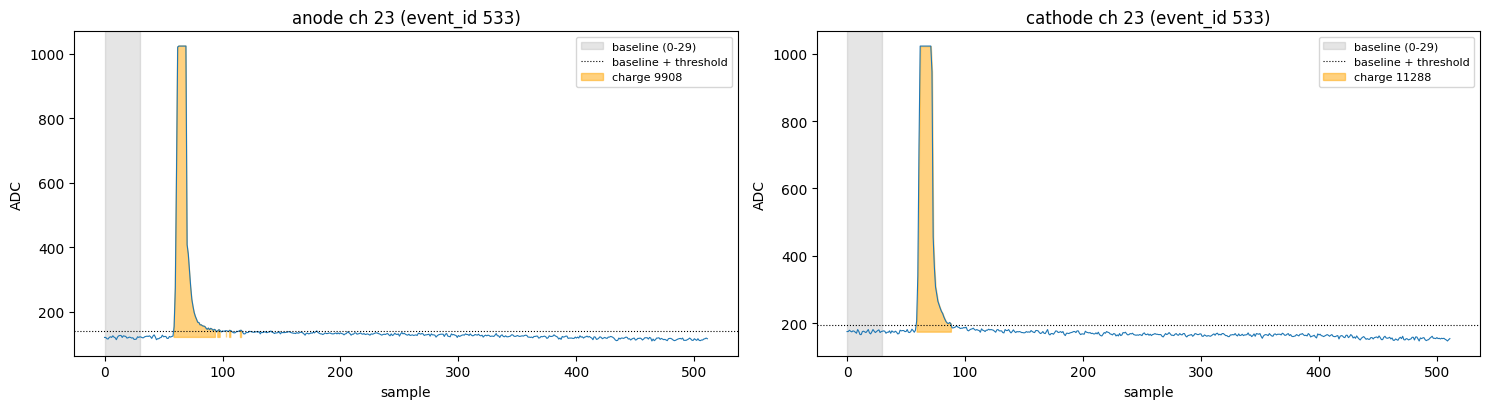

In [4]:
r = ROOT.RDataFrame("RawTreeWriter_sm3/raw", str(OUT_RAW)).AsNumpy(["event_id", "fadc_ch", "fadc_wave"])
BASE, THR = 30, 20.0

def charges(chs, wave):
    """CalcFADC と同じ計算: ch ごとの (ベースライン, 電荷)。浮動小数点の丸めまで同じになるよう、C++ と同じ順に足す"""
    w = np.asarray(wave, dtype=float).reshape(-1, 512)
    base = np.zeros(len(w))
    for k in range(BASE):
        base += w[:, k] / BASE             # mean += wave / base_window
    q = np.zeros(len(w))
    for k in range(BASE, 512):
        d = w[:, k] - base
        q += np.where(d > THR, d, 0.0)     # charge += wave - mean (wave - mean > threshold のサンプル)
    return base, q

fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, side in zip(axs, ["anode", "cathode"]):
    best = None
    for e, (chs, wave) in enumerate(zip(r["fadc_ch"], r["fadc_wave"])):
        chs = np.asarray(chs); base, q = charges(chs, wave)
        sel = (chs < 48) if side == "anode" else (chs >= 48)
        if sel.any():
            i = np.where(sel)[0][np.argmax(q[sel])]
            if best is None or q[i] > best[0] and q[i] < 2e4:
                best = (q[i], e, i, base[i])
        if e > 1500:
            break
    q, e, i, b = best
    w = np.asarray(r["fadc_wave"][e]).reshape(-1, 512)[i]
    ch = int(np.asarray(r["fadc_ch"][e])[i])
    ax.plot(w, lw=0.8); ax.axvspan(0, BASE, color="gray", alpha=0.2, label="baseline (0-29)")
    ax.axhline(b + THR, color="k", ls=":", lw=0.8, label="baseline + threshold")
    ax.fill_between(np.arange(BASE, 512), b, w[BASE:], where=w[BASE:] - b > THR, color="orange", alpha=0.5, label=f"charge {q:.0f}")
    ax.set_title(f"{side} ch {ch if ch < 48 else ch - 48} (event_id {r['event_id'][e]})"); ax.set_xlabel("sample"); ax.set_ylabel("ADC"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. 手で計算して比べる

上の式で 5000 イベントの全 ch の電荷を計算し、`make_tpc_spec1hit.py` の `Charge_Anode`(電荷のある ch の電荷 × ch の 2 次元ヒストグラム)と比べます。
`make_tpc_spec1hit.py` の電荷の計算は CalcFADC::IntegWave と同じ C++ です。ヒストグラムのビンの中身がすべて一致します。

ADC の値は整数なので、ちょうど「ベースライン + 20」になるサンプルがよくあります。ベースラインの足し方(1 サンプルずつ 30 で割って足す)が違うと、
浮動小数点の丸めでそのサンプルを足すかどうかが変わり、少しずれます。そのため上の関数は C++ と同じ順に計算しています。

In [5]:
SPEC1HIT = REPO / "scripts" / "calib" / "make_tpc_spec1hit.py"

def spec1hit(raw, out):
    """make_tpc_spec1hit.py を実行する(出力が既にあれば何もしない)"""
    cmd = [sys.executable, str(SPEC1HIT), "-o", str(out), str(raw)]
    print(" ".join(cmd))
    if not out.exists():
        subprocess.run(cmd, check=True)

SPEC5 = CACHE / "tpc_20260623_raw_spec1hit.root"
spec1hit(OUT_RAW, SPEC5)
f5 = ROOT.TFile(str(SPEC5))
ref, ex, ey = th2(f5.Get("Charge_Anode"))
qs, cs = [], []
for chs, wave in zip(r["fadc_ch"], r["fadc_wave"]):
    chs = np.asarray(chs); _, q = charges(chs, wave)
    a = (chs < 48) & (q > 0)
    qs.append(q[a]); cs.append(chs[a])
mine = np.histogram2d(np.concatenate(qs), np.concatenate(cs), bins=[ex, ey])[0]
print("anode charges:", int(mine.sum()), " Charge_Anode entries:", int(ref.sum()), " bins that differ:", int((mine != ref).sum()))

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_tpc_spec1hit.py -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw_spec1hit.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw.root


anode charges: 6317  Charge_Anode entries: 6317  bins that differ: 0


## 5. 電荷のある ch の数

1 イベントで電荷のある ch の数です。アノード 1 ch・カソード 1 ch のイベントは全体の 3 割ほどで、どのイベントも後ろのモジュールに渡ります(1-hit スペクトルは、カソードをアノードと同じパネルの中だけで数えるので、数が少し違う)。

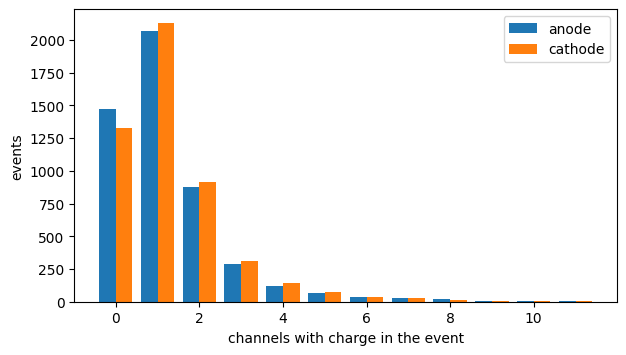

anode 1 ch and cathode 1 ch: 1446 of 5000 events


In [6]:
na = [int(((np.asarray(c) < 48) & (charges(c, w)[1] > 0)).sum()) for c, w in zip(r["fadc_ch"], r["fadc_wave"])]
nc = [int(((np.asarray(c) >= 48) & (charges(c, w)[1] > 0)).sum()) for c, w in zip(r["fadc_ch"], r["fadc_wave"])]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist([na, nc], bins=np.arange(-0.5, 12.5), label=["anode", "cathode"])
ax.set_xlabel("channels with charge in the event"); ax.set_ylabel("events"); ax.legend()
plt.show()
print("anode 1 ch and cathode 1 ch:", sum(1 for a, c in zip(na, nc) if a == 1 and c == 1), "of", len(na), "events")

## 6. ベースラインと電荷

生データのツリーの先頭 5 万イベントから `make_tpc_spec1hit.py` で作った `Baseline_Anode`, `Baseline_Cathode`, `Charge_Anode`, `Charge_Cathode` です(電荷のある ch だけ)。
カソードは反転しているので、ベースラインは `1023 − 約 850 ≈ 170` 付近に来ます。
ターミナルでは、リポジトリで次を実行するのと同じです。

```bash
python3 run_script/run_chain.py smile3_raw -o tpc_20260623_raw_n50000.root -n 50000 --data-dir test.data/run_20260623T072649Z --compression 505
/usr/bin/python3 scripts/calib/make_tpc_spec1hit.py -o tpc_20260623_spec1hit.root tpc_20260623_raw_n50000.root
```

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_raw -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw_n50000.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 50000 --compression 505
/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_tpc_spec1hit.py -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_spec1hit.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw_n50000.root


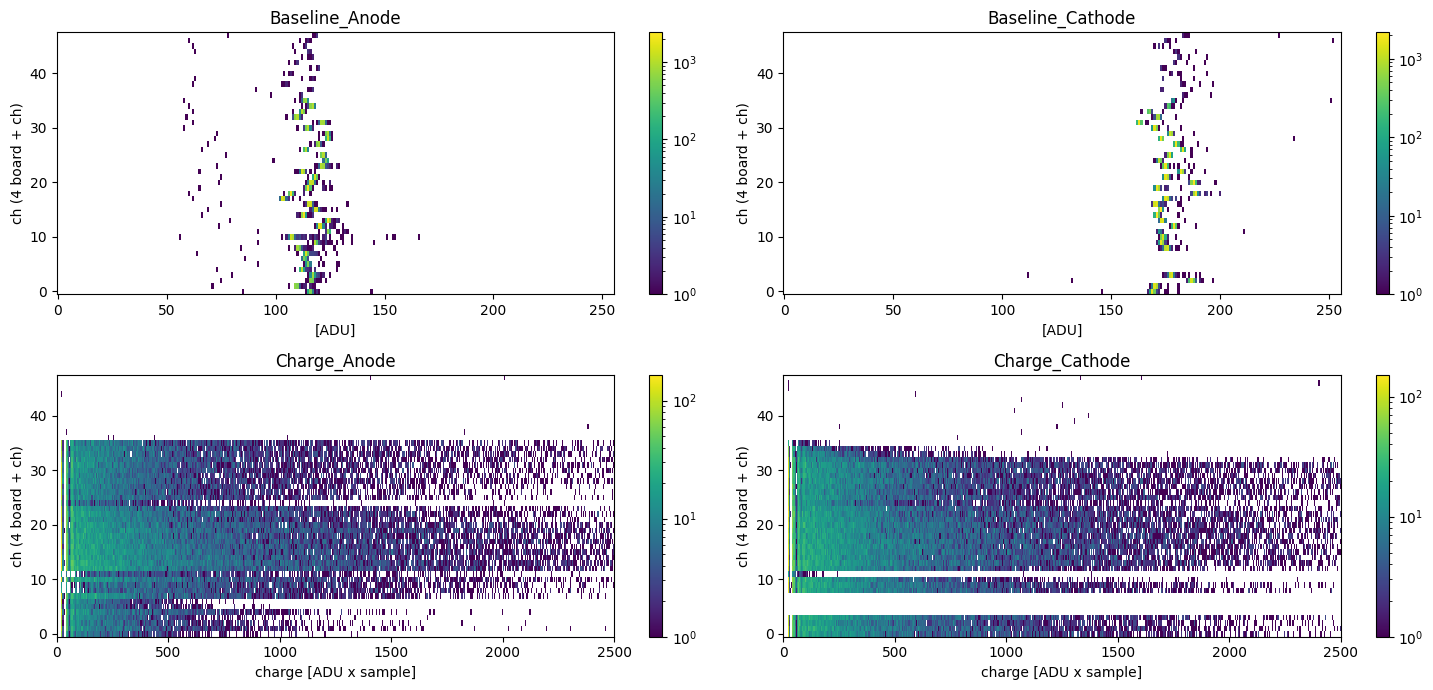

In [7]:
OUT_RAW50 = CACHE / "tpc_20260623_raw_n50000.root"
run_chain("smile3_raw", OUT_RAW50, "-n", "50000", "--compression", "505")
SPEC = CACHE / "tpc_20260623_spec1hit.root"
spec1hit(OUT_RAW50, SPEC)
FS = ROOT.TFile(str(SPEC))
fig, axs = plt.subplots(2, 2, figsize=(15, 7))
for ax, name in zip(axs.flat, ["Baseline_Anode", "Baseline_Cathode", "Charge_Anode", "Charge_Cathode"]):
    a, ex, ey = th2(FS.Get(name))
    if name.startswith("Charge"):
        a, ex = a[:500], ex[:501]
    m = ax.pcolormesh(ex, ey, a.T, norm=LogNorm(vmin=1), shading="flat")
    ax.set_title(name); ax.set_xlabel("[ADU]" if "Base" in name else "charge [ADU x sample]"); ax.set_ylabel("ch (4 board + ch)")
    fig.colorbar(m, ax=ax)
fig.tight_layout(); plt.show()

## 7. 1-hit スペクトル

`make_tpc_spec1hit.py` の、ボードの組ごとの 1-hit スペクトル(`Anode_1Hit_board_Ai_Cj`)です。ゲインマップ(`TPC_Calibration` の `ParameterFile`)は、
このスペクトルの線源のピークから ch の組ごとに作ります(EricaNext_try の `4_MakeCalibration/GainMap`)。このランの線源のピークは、まだ確かめていません。

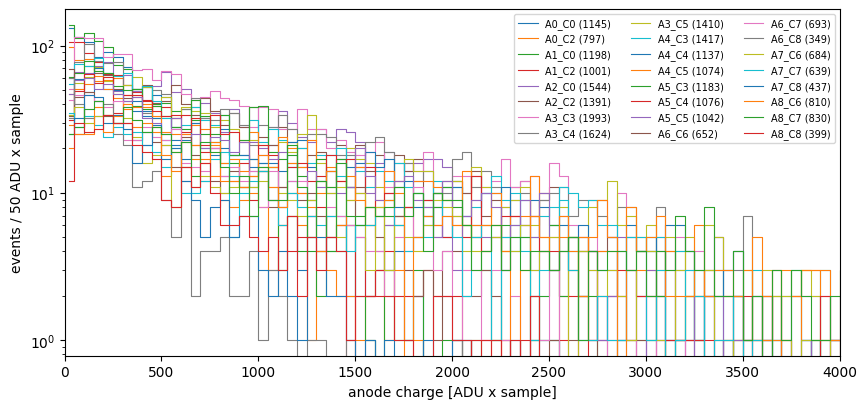

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for k in FS.GetListOfKeys():
    if k.GetName().startswith("Anode_1Hit_board_"):
        y, x = th1(k.ReadObj())
        y, x = y.reshape(-1, 10).sum(1), x.reshape(-1, 10).mean(1)   # 10 ビンずつまとめる(50 ADU × サンプル)
        if y.sum() > 200:
            ax.step(x, y, where="mid", lw=0.8, label=k.GetName()[17:] + f" ({int(y.sum())})")
ax.set_xlim(0, 4000); ax.set_yscale("log"); ax.set_xlabel("anode charge [ADU x sample]"); ax.set_ylabel("events / 50 ADU x sample")
ax.legend(ncol=3, fontsize=7); plt.show()

## 8. パラメータ

In [9]:
show_params("smile3_tpc_only", "CalcFADC")

base_window = 30.0 [samples (20 ns each)]
    ベースライン(波形の最初のこのサンプル数の平均)[samples, 1 サンプル 20 ns]
threshold = 20.0 [ADU (above the baseline)]
    電荷として積分するサンプルの閾値(ベースラインからの高さ)[ADU]
